# Car Price Prediction

### На онлайн-площадках продажи автомобилей пользователи часто сталкиваются с трудностью оценки справедливой стоимости автомобиля. Цена может зависеть от множества факторов: возраста автомобиля, пробега, мощности двигателя, комплектации и состояния. Наличие модели, автоматически оценивающей рыночную стоимость автомобиля, может значительно повысить прозрачность рынка и улучшить пользовательский опыт.


### Постановка задачи

#### Цель проекта — разработать модель для оценки рыночной стоимости подержанного автомобиля на основе его характеристик. 

#### Такая модель может использоваться на онлайн-платформах продажи автомобилей для:
    - помощи продавцам при определении конкурентной цены объявления
    - помощи покупателям в оценке адекватности указанной цены
    - выявления аномально завышенных или заниженных предложений

#### В рамках проекта необходимо:
    1) провести исследовательский анализ данных (EDA);
    2) определить факторы, влияющие на стоимость автомобиля;
    3) подготовить признаки и обработать категориальные переменные;
    4) построить модель множественной линейной регрессии;
    5) оценить качество модели и интерпретировать результаты.

In [253]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [230]:
df = pd.read_csv('vehicle_price_prediction.csv')

In [30]:
df.head()

,make,model,year,mileage,engine_hp,transmission,fuel_type,drivetrain,body_type,exterior_color,interior_color,owner_count,accident_history,seller_type,condition,trim,vehicle_age,mileage_per_year,brand_popularity,price
0,Volkswagen,Jetta,2016,183903,173,Manual,Electric,RWD,Sedan,Blue,Brown,5,Unknown,Dealer,Excellent,EX,9,20433.666667,0.040054,7208.52
1,Lexus,RX,2010,236643,352,Manual,Gasoline,FWD,Sedan,Silver,Beige,5,Minor,Dealer,Good,LX,15,15776.200000,0.039921,6911.81
2,Subaru,Crosstrek,2016,103199,188,Automatic,Diesel,AWD,Sedan,Silver,Beige,5,Unknown,Dealer,Excellent,Touring,9,11466.555556,0.040230,11915.63
3,Cadillac,Lyriq,2016,118889,338,Manual,Gasoline,AWD,SUV,Black,Gray,3,Unknown,Private,Good,Base,9,13209.888889,0.039847,25984.79
4,Toyota,Highlander,2018,204170,196,Manual,Diesel,FWD,Sedan,Red,Brown,5,Minor,Dealer,Excellent,Sport,7,29167.142857,0.039627,8151.30


In [249]:
df.shape

# Имеем 1000000 строк и 20 колонок в датасете

(1000000, 20)

In [250]:
df.info()

# Данные уже почти готовы, нужно убрать нулл значения в accident_history, но это будет позже

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   make              1000000 non-null  object 
 1   model             1000000 non-null  object 
 2   year              1000000 non-null  int64  
 3   mileage           1000000 non-null  int64  
 4   engine_hp         1000000 non-null  int64  
 5   transmission      1000000 non-null  object 
 6   fuel_type         1000000 non-null  object 
 7   drivetrain        1000000 non-null  object 
 8   body_type         1000000 non-null  object 
 9   exterior_color    1000000 non-null  object 
 10  interior_color    1000000 non-null  object 
 11  owner_count       1000000 non-null  int64  
 12  accident_history  249867 non-null   object 
 13  seller_type       1000000 non-null  object 
 14  condition         1000000 non-null  object 
 15  trim              1000000 non-null  object 
 16  v

In [255]:
df.isna().sum()

make                     0
model                    0
year                     0
mileage                  0
engine_hp                0
transmission             0
fuel_type                0
drivetrain               0
body_type                0
exterior_color           0
interior_color           0
owner_count              0
accident_history    750133
seller_type              0
condition                0
trim                     0
vehicle_age              0
mileage_per_year         0
brand_popularity         0
price                    0
dtype: int64

In [256]:
df.describe()

# Тут тоже никаких проблем, все числовые данные логичны и не противоречат здравому смыслу

,year,mileage,engine_hp,owner_count,vehicle_age,mileage_per_year,brand_popularity,price
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,2017.453816,112660.126464,235.664301,3.477846,7.585987,14540.674200,0.040001,20329.302593
std,3.902285,72088.236925,93.614773,1.544856,3.829534,6108.901522,0.000234,13644.467189
min,2000.000000,500.000000,90.000000,1.000000,1.000000,33.333333,0.039318,1500.000000
25%,2015.000000,57654.000000,162.000000,2.000000,5.000000,10487.633523,0.039842,10324.527500
50%,2018.000000,103331.000000,215.000000,4.000000,7.000000,14688.118056,0.040022,17864.740000
75%,2020.000000,157865.000000,300.000000,5.000000,10.000000,18685.942308,0.040148,27601.402500
max,2025.000000,300000.000000,581.000000,5.000000,25.000000,55391.000000,0.040484,93422.090000


In [252]:
# Проверка дубликатов
dup = df.duplicated().sum()
print(f'Дубликатов = {dup}')

Дубликатов = 0


<Axes: >

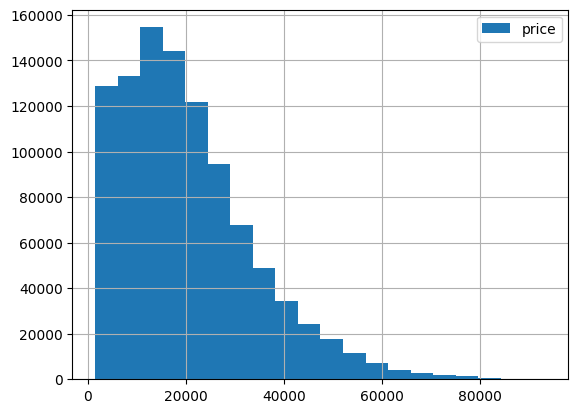

In [265]:
# Распределение цены имеет правостороннюю ассиметрию, большинство авто в среднем ценовом сегменте, но имеется хвост из дорогих авто
df['price'].hist(bins=20, legend=True)

#### Изучим некоторые прикзнаки и их влияние на цену

Text(0, 0.5, 'Price')

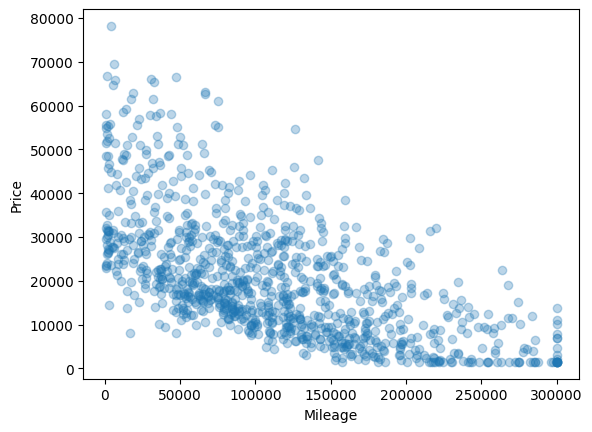

In [273]:
sample = df.sample(1000)

plt.scatter(sample['mileage'], sample['price'], alpha=0.3)
plt.xlabel('Mileage')
plt.ylabel('Price')

Text(0, 0.5, 'Price')

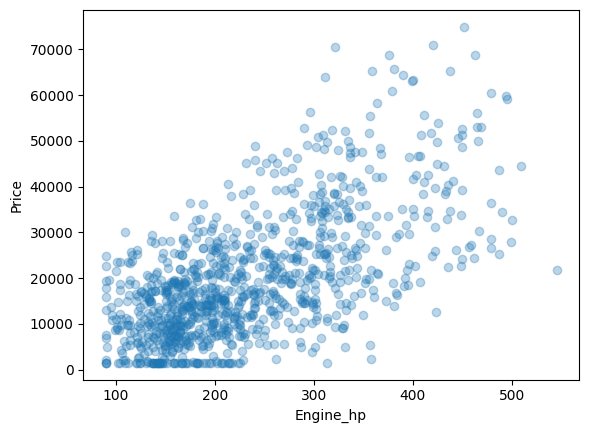

In [272]:
plt.scatter(sample['engine_hp'], sample['price'], alpha=0.3)
plt.xlabel('Engine_hp')
plt.ylabel('Price')

Text(0, 0.5, 'Price')

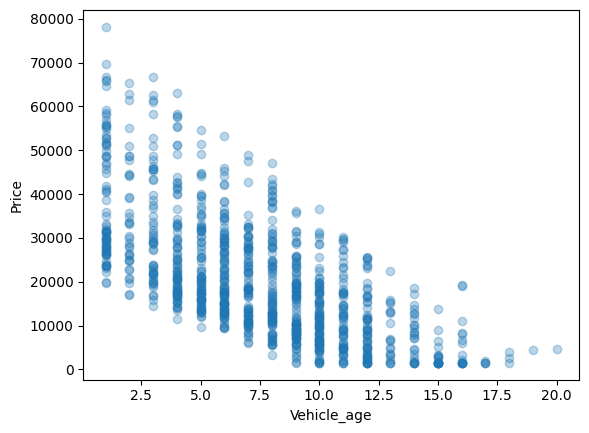

In [275]:
plt.scatter(sample['vehicle_age'], sample['price'], alpha=0.3)
plt.xlabel('Vehicle_age')
plt.ylabel('Price')

#### Можно сделать вывод: увеличение пробега негативно сказывается на цене, как и увеличение возраста авто, в то время как большая мощность в автомобиле, как правило увеличивает его ценность

#### Изучим категориальные признаки

In [300]:
df['trim'].unique()

array(['EX', 'LX', 'Touring', 'Base', 'Sport', 'Limited'], dtype=object)

In [282]:
# Сгруппирую по категории trim, и посмотрю среднюю цену на авто в каждой категории
df.groupby('trim')['price'].mean().sort_values().round(2)

trim
EX         20279.66
Limited    20305.00
LX         20312.87
Sport      20331.68
Base       20371.73
Touring    20374.90
Name: price, dtype: float64

<Axes: xlabel='trim', ylabel='price'>

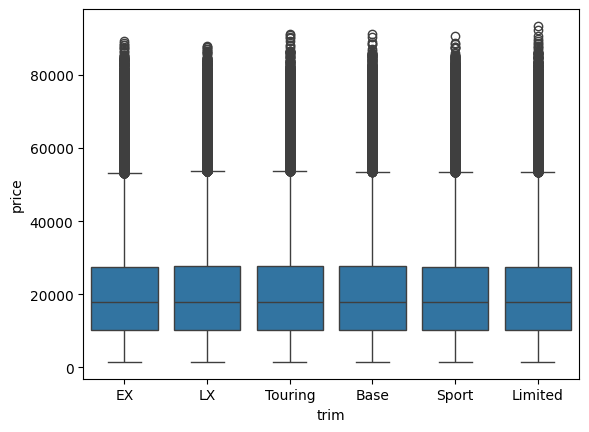

In [285]:
sns.boxplot(x="trim", y="price", data=df)

##### В данном случае в каждой комплектации средняя цена, медиана, квартили и выбросы примерно одинаковы, скорее всего влияние комплектации на модель будет не так значительна

In [287]:
df.groupby('seller_type')['price'].mean().round(2)

seller_type
Dealer     20628.46
Private    19632.23
Name: price, dtype: float64

<Axes: xlabel='seller_type', ylabel='price'>

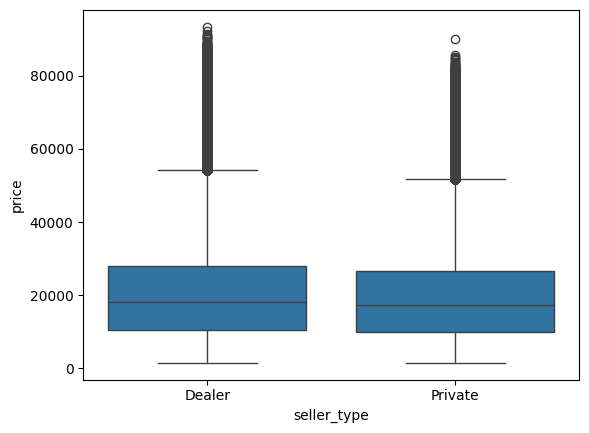

In [288]:
sns.boxplot(x="seller_type", y="price", data=df)

<Axes: >

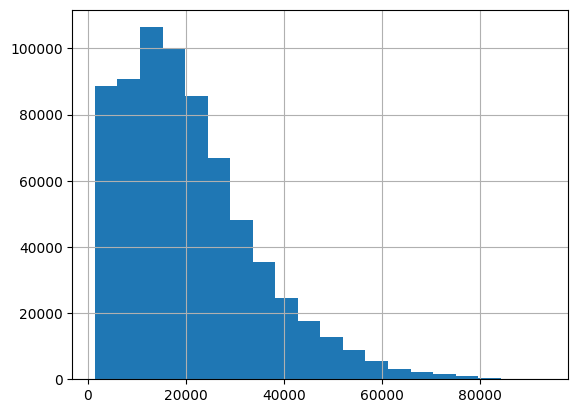

In [290]:
df[df['seller_type'] == 'Dealer']['price'].hist(bins=20)

<Axes: >

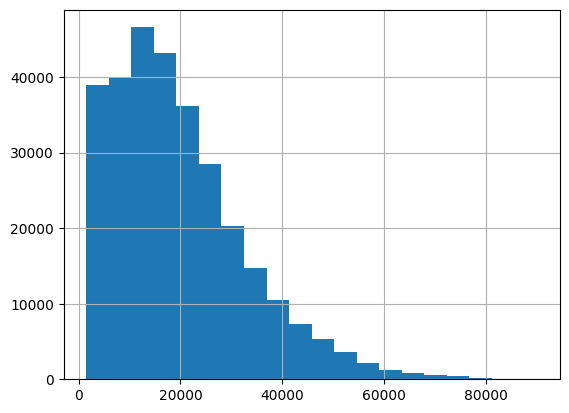

In [293]:
df[df['seller_type'] == 'Private']['price'].hist(bins=20)

##### Для типа продавца аналогичная ситуация, распределения цен очень схожи, параметр не будет оказывать сильное влияние

In [299]:
df.groupby('condition')['price'].mean().sort_values()

condition
Fair         18113.479041
Good         20125.600801
Excellent    21136.661209
Name: price, dtype: float64

##### Средняя цена автомобиля увеличивается с улучшением состояния. Автомобили в состоянии Excellent в среднем стоят примерно на 3000$ дороже автомобилей в состоянии Fair. Это подтверждает, что состояние автомобиля является значимым фактором формирования цены.

### Уберем пропуски из accident_history, логическим методом отберем колонки подходящие для модели

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   make              1000000 non-null  object 
 1   model             1000000 non-null  object 
 2   year              1000000 non-null  int64  
 3   mileage           1000000 non-null  int64  
 4   engine_hp         1000000 non-null  int64  
 5   transmission      1000000 non-null  object 
 6   fuel_type         1000000 non-null  object 
 7   drivetrain        1000000 non-null  object 
 8   body_type         1000000 non-null  object 
 9   exterior_color    1000000 non-null  object 
 10  interior_color    1000000 non-null  object 
 11  owner_count       1000000 non-null  int64  
 12  accident_history  249867 non-null   object 
 13  seller_type       1000000 non-null  object 
 14  condition         1000000 non-null  object 
 15  trim              1000000 non-null  object 
 16  v

In [24]:
df['accident_history'].unique()

array([nan, 'Minor', 'Major'], dtype=object)

In [25]:
df['accident_history'] = df['accident_history'].fillna('Unknown')

In [13]:
df['trim'].unique()

array(['EX', 'LX', 'Touring', 'Base', 'Sport', 'Limited'], dtype=object)

In [229]:
# Отбираю колонки которые будут использоваться для модели

preDf = df[
    ['vehicle_age', 'mileage', 'engine_hp', 'transmission', 'fuel_type',
     'drivetrain', 'owner_count', 'accident_history',
     'seller_type', 'condition', 'trim',
     'brand_popularity', 'price']
]

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [27]:
preDf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   vehicle_age       1000000 non-null  int64  
 1   mileage           1000000 non-null  int64  
 2   engine_hp         1000000 non-null  int64  
 3   transmission      1000000 non-null  object 
 4   fuel_type         1000000 non-null  object 
 5   drivetrain        1000000 non-null  object 
 6   owner_count       1000000 non-null  int64  
 7   accident_history  1000000 non-null  object 
 8   seller_type       1000000 non-null  object 
 9   condition         1000000 non-null  object 
 10  trim              1000000 non-null  object 
 11  brand_popularity  1000000 non-null  float64
 12  price             1000000 non-null  float64
dtypes: float64(2), int64(4), object(7)
memory usage: 99.2+ MB


In [29]:
preDf.head()

,vehicle_age,mileage,engine_hp,transmission,fuel_type,drivetrain,owner_count,accident_history,seller_type,condition,trim,brand_popularity,price
0,9,183903,173,Manual,Electric,RWD,5,Unknown,Dealer,Excellent,EX,0.040054,7208.52
1,15,236643,352,Manual,Gasoline,FWD,5,Minor,Dealer,Good,LX,0.039921,6911.81
2,9,103199,188,Automatic,Diesel,AWD,5,Unknown,Dealer,Excellent,Touring,0.040230,11915.63
3,9,118889,338,Manual,Gasoline,AWD,3,Unknown,Private,Good,Base,0.039847,25984.79
4,7,204170,196,Manual,Diesel,FWD,5,Minor,Dealer,Excellent,Sport,0.039627,8151.30


#### Разделим данные для обучения и валедации модели

In [ ]:
# X - матрица фич, y - вектор цен
X = preDf.drop('price', axis=1)
y = preDf['price']

# 70% для обучения, 30% для валидации
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

X_train.head()

#### Преобразуем нечисловые поля к числовым методом OneHotEncoding

In [ ]:
X_train = pd.get_dummies(X_train, columns=[
    'transmission',
    'fuel_type',
    'drivetrain',
    'seller_type',
    'condition',
    'trim',
    'accident_history'
])

X_val = pd.get_dummies(X_val, columns=[
    'transmission',
    'fuel_type',
    'drivetrain',
    'seller_type',
    'condition',
    'trim',
    'accident_history' 
])

In [178]:
X_train.head()

,vehicle_age,mileage,engine_hp,owner_count,brand_popularity,transmission_Automatic,transmission_Manual,fuel_type_Diesel,fuel_type_Electric,fuel_type_Gasoline,...,condition_Good,trim_Base,trim_EX,trim_LX,trim_Limited,trim_Sport,trim_Touring,accident_history_Major,accident_history_Minor,accident_history_Unknown
506532,7,62431,316,5,0.039847,0,1,0,1,0,...,0,0,0,0,1,0,0,0,0,1
327991,6,44572,143,2,0.039318,0,1,0,1,0,...,1,0,1,0,0,0,0,0,0,1
715937,10,82304,162,3,0.040217,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,1
860726,14,202894,345,5,0.040226,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
78617,11,140159,236,5,0.039921,1,0,0,0,1,...,1,0,0,1,0,0,0,0,1,0


In [140]:
bool_cols = X_train.select_dtypes(include='bool').columns

X_train[bool_cols] = X_train[bool_cols].astype(int)
X_val[bool_cols] = X_val[bool_cols].astype(int)

In [142]:
X_train.corr()

,vehicle_age,mileage,engine_hp,owner_count,brand_popularity,transmission_Automatic,transmission_Manual,fuel_type_Diesel,fuel_type_Electric,fuel_type_Gasoline,...,condition_Good,trim_Base,trim_EX,trim_LX,trim_Limited,trim_Sport,trim_Touring,accident_history_Major,accident_history_Minor,accident_history_Unknown
vehicle_age,1.000000,0.783104,-0.000123,0.646059,0.000396,0.001439,-0.001439,-0.001879,0.002797,-0.000996,...,0.000679,0.000024,0.001198,-0.000333,0.000153,0.000010,-0.001051,0.000487,0.000157,-0.000390
mileage,0.783104,1.000000,-0.000045,0.513638,-0.001371,0.001632,-0.001632,-0.001366,0.002292,-0.000990,...,0.001495,-0.000135,0.001496,0.000672,0.000233,-0.000975,-0.001294,0.000975,-0.000389,-0.000129
engine_hp,-0.000123,-0.000045,1.000000,0.000088,0.077437,-0.003218,0.003218,-0.036754,0.070536,-0.035775,...,0.001765,0.001423,-0.000700,0.000320,-0.001415,-0.000296,0.000667,0.001764,0.001017,-0.001825
owner_count,0.646059,0.513638,0.000088,1.000000,-0.000164,0.002247,-0.002247,-0.001311,0.001319,-0.000044,...,-0.001250,0.000966,0.002237,-0.000960,-0.000429,-0.000697,-0.001117,-0.001069,-0.000331,0.000842
brand_popularity,0.000396,-0.001371,0.077437,-0.000164,1.000000,0.001147,-0.001147,-0.025843,0.052805,-0.028456,...,0.000728,0.001003,-0.001040,0.001680,-0.000017,-0.001031,-0.000598,-0.000025,0.000370,-0.000330
transmission_Automatic,0.001439,0.001632,-0.003218,0.002247,0.001147,1.000000,-1.000000,-0.001173,-0.000415,0.001600,...,-0.002011,0.000998,0.000810,-0.000462,-0.001182,-0.000272,0.000109,-0.000369,-0.001510,0.001581
transmission_Manual,-0.001439,-0.001632,0.003218,-0.002247,-0.001147,-1.000000,1.000000,0.001173,0.000415,-0.001600,...,0.002011,-0.000998,-0.000810,0.000462,0.001182,0.000272,-0.000109,0.000369,0.001510,-0.001581
fuel_type_Diesel,-0.001879,-0.001366,-0.036754,-0.001311,-0.025843,-0.001173,0.001173,1.000000,-0.514719,-0.471336,...,-0.000331,0.000162,0.000790,-0.000788,0.002054,-0.002187,-0.000037,-0.000745,-0.000739,0.001057
fuel_type_Electric,0.002797,0.002292,0.070536,0.001319,0.052805,-0.000415,0.000415,-0.514719,1.000000,-0.513545,...,0.001973,0.000994,0.001435,-0.001111,-0.000047,-0.000263,-0.001006,-0.000916,0.000281,0.000199
fuel_type_Gasoline,-0.000996,-0.000990,-0.035775,-0.000044,-0.028456,0.001600,-0.001600,-0.471336,-0.513545,1.000000,...,-0.001698,-0.001185,-0.002267,0.001931,-0.002007,0.002460,0.001072,0.001688,0.000451,-0.001263


#### Присутствует мультиколлениарность mileage и vehicle_age, что логично, но в учебных целях оставим как есть

In [143]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 700000 entries, 506532 to 121958
Data columns (total 27 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   vehicle_age               700000 non-null  int64  
 1   mileage                   700000 non-null  int64  
 2   engine_hp                 700000 non-null  int64  
 3   owner_count               700000 non-null  int64  
 4   brand_popularity          700000 non-null  float64
 5   transmission_Automatic    700000 non-null  int64  
 6   transmission_Manual       700000 non-null  int64  
 7   fuel_type_Diesel          700000 non-null  int64  
 8   fuel_type_Electric        700000 non-null  int64  
 9   fuel_type_Gasoline        700000 non-null  int64  
 10  drivetrain_AWD            700000 non-null  int64  
 11  drivetrain_FWD            700000 non-null  int64  
 12  drivetrain_RWD            700000 non-null  int64  
 13  seller_type_Dealer        700000 non-null  i

In [179]:
X_train.head()

,vehicle_age,mileage,engine_hp,owner_count,brand_popularity,transmission_Automatic,transmission_Manual,fuel_type_Diesel,fuel_type_Electric,fuel_type_Gasoline,...,condition_Good,trim_Base,trim_EX,trim_LX,trim_Limited,trim_Sport,trim_Touring,accident_history_Major,accident_history_Minor,accident_history_Unknown
506532,7,62431,316,5,0.039847,0,1,0,1,0,...,0,0,0,0,1,0,0,0,0,1
327991,6,44572,143,2,0.039318,0,1,0,1,0,...,1,0,1,0,0,0,0,0,0,1
715937,10,82304,162,3,0.040217,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,1
860726,14,202894,345,5,0.040226,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
78617,11,140159,236,5,0.039921,1,0,0,0,1,...,1,0,0,1,0,0,0,0,1,0


#### Создаем модель

In [180]:
model = LinearRegression()

In [181]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [182]:
y_pred = model.predict(X_val)

In [193]:
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)
print(f'MAE = {mae:.2f}')
print(f'R2_score = {r2:.2f}')

# В целом абсолютное среднее отклонение приемлемо, коэф детерминации отличный

MAE = 3043.13
R2_score = 0.91


In [186]:
comparison = pd.DataFrame({
    "real_price": y_val,
    "predicted_price": y_pred
})

comparison.head(10)

,real_price,predicted_price
987231,19226.82,17338.019763
79954,60435.02,50943.706787
567130,28708.28,33066.767293
500891,18938.64,18978.913288
55399,18487.37,23874.272502
135049,38419.94,37040.284037
733378,9279.05,7131.338752
732057,16740.43,19030.792486
51333,24464.90,32613.154303
731479,19586.85,23162.694043


In [200]:
comparison_sorted = comparison.sort_values("real_price")
comparison_sorted["pred_smooth"] = (
    comparison_sorted["predicted_price"]
    .rolling(window=200)
    .mean()
)

Text(0, 0.5, 'Price')

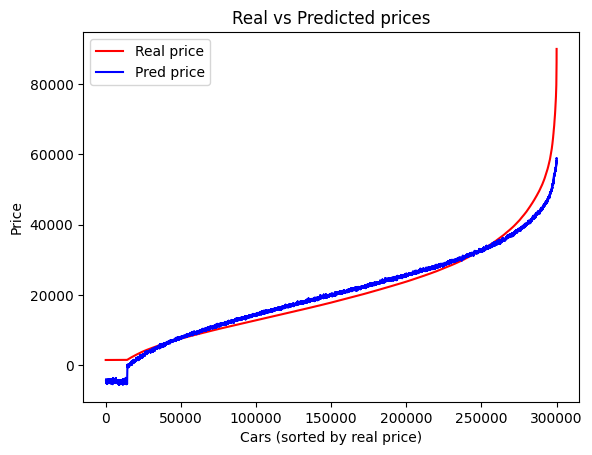

In [302]:
plt.plot(comparison_sorted['real_price'].values, label="Real price", color="red")
plt.plot(comparison_sorted['pred_smooth'].values, label='Pred price', color='blue')

plt.legend()
plt.title("Real vs Predicted prices")
plt.xlabel("Cars (sorted by real price)")
plt.ylabel("Price")

In [228]:
# Пример использования, посмотрим предсказание цены по некоторым данным из валидационных данных и сравним с настоящей ценной

print(f'predict price: {model.predict(X_val.loc[[987231]])[0]:.2f}')
print(f'real price: {y_val.loc[987231]:.2f}')

predict price: 17338.02
real price: 19226.82


### В ходе работы была разработана модель линейной регрессии для прогнозирования стоимости автомобилей. Модель показала высокое качество предсказания: коэффициент детерминации R² составил 0.91, а средняя абсолютная ошибка — около 3043$.

### Дополнительно можно вывести список параметров, которые наиболее повлияли на модель

In [305]:
coeffs = pd.Series(model.coef_, index=X_train.columns)
coeffs.sort_values(ascending=False)

brand_popularity            283171.794717
accident_history_Unknown      2440.181977
condition_Excellent           1354.231832
seller_type_Dealer             484.652246
accident_history_Minor         354.682663
condition_Good                 329.724885
engine_hp                       95.074612
fuel_type_Electric              80.787815
drivetrain_RWD                  25.648429
trim_LX                         14.188243
trim_Touring                    13.563168
trim_Base                       12.970531
drivetrain_FWD                  12.565017
transmission_Automatic           2.831371
mileage                         -0.048471
transmission_Manual             -2.831371
trim_Limited                    -6.422468
trim_EX                        -12.845302
trim_Sport                     -21.454172
fuel_type_Diesel               -35.459896
drivetrain_AWD                 -38.213447
fuel_type_Gasoline             -45.327918
owner_count                   -295.454604
seller_type_Private           -484

#### Анализ коэффициентов линейной регрессии показал, что наибольшее влияние на цену автомобиля оказывают такие характеристики как популярность бренда, история аварий, возраст автомобиля и его состояние. Менее значимое влияние оказывают тип трансмиссии, привод и комплектация автомобиля.

#### Полученные результаты позволяют рекомендовать платформам продажи автомобилей делать такие характеристики как возраст автомобиля, пробег, состояние и история аварий обязательными для заполнения при создании объявления, так как именно эти параметры оказывают наибольшее влияние на формирование цены.